# A traffic jump: is this the new normal?

**On ordinary days, a forecaster that follows the last three days is as good as any of four, and a four-week average is the worst. Three days into a jump the order turns over: the last three days are off by a factor of 3.8 and the four-week average by 2.3. The usual backtest cannot show this, because jumps are 0.2% of its days. A forecaster that learns from earlier jumps how much of a jump to carry forward gets to 2.0. Two weeks later, the ordinary order is back.**

A page, a product or a feature takes off, and someone asks whether this is the new normal. It is the day a forecast matters most and the day a backtest has the least to say about. This notebook runs the same forecasters twice, on every week and on the days an alarm rings, and then builds the forecaster the second run asks for.

*Data: daily views of 136 Wikipedia pages, July 2015 to September 2017, from the Monash forecasting archive ([source and license](data/README.md#wikipedia-views)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import Pipeline, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

We wanted signups after a product launch. We found none published under a license that lets a sample be shared, so this is the closest public thing: how many times a day each of 136 Wikipedia pages was viewed, over 26 months. Pages take off all the time, usually when their subject is in the news, and every one of those jumps is on record with what came after.

The job starts with an alarm. A page that usually gets a few hundred views a day has had three days in a row at three times that or more. Whoever looks after capacity, moderation or support now needs a number for each of the next four weeks. "Usually" is the median of the eight weeks before the three days.

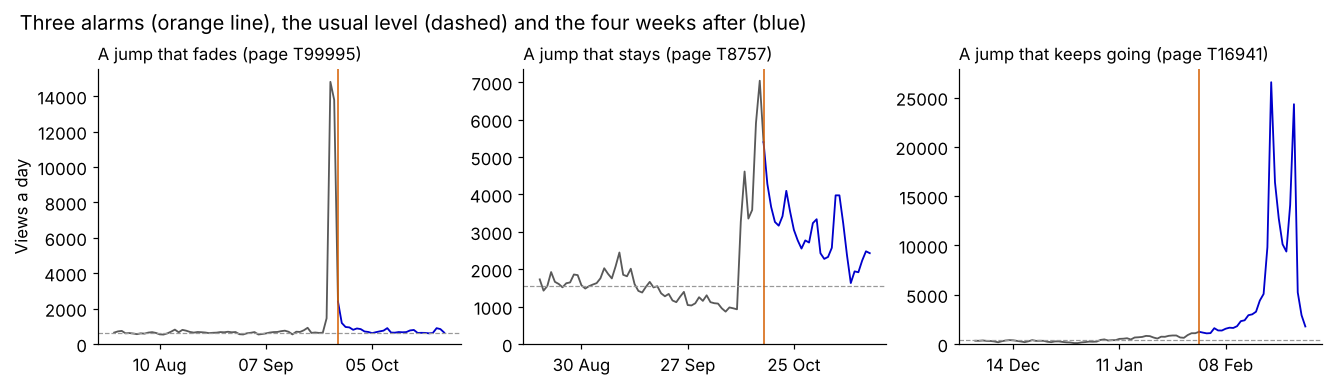

136 pages, 803 days, 1 July 2015 to 10 September 2017.
The alarm rings 240 times: 125 times before the test year, 95 times in it.
In the test year that is 95 of 51,000 page-days, or 0.2%.


In [2]:
views = load("wikipedia-views")

USUAL_DAYS = 56     # the usual level is the median of this many days before the jump
JUMP_DAYS = 3       # the alarm rings after this many days in a row ...
JUMP_SIZE = 3       # ... at this many times the usual level or more,
BUSY = 100          # on a page with at least this many views on a usual day
HORIZON = 28


def usual_level(history):
    "The median of the eight weeks before the last three days."
    return float(np.median(history[-JUMP_DAYS - USUAL_DAYS:-JUMP_DAYS]))


def alarms(page):
    "For one page, the number of days of history each time the alarm rings."
    values, rings, last = page.to_numpy(float), [], -USUAL_DAYS
    for days in range(USUAL_DAYS + JUMP_DAYS, len(values) + 1):
        history = values[:days]
        usual = usual_level(history)
        if usual >= BUSY and (history[-JUMP_DAYS:] >= JUMP_SIZE * usual).all():
            if days - last > USUAL_DAYS:      # ring once for a jump, not on each of its days
                rings.append(days)
            last = days
    return rings


first = views.index.get_loc(pd.Timestamp("2016-09-01"))       # the test year starts here
latest = len(views) - HORIZON - 14                           # leaves six weeks after an alarm
rings = [(page, days) for page in views.columns for days in alarms(views[page])]
test = [(page, days) for page, days in rings if first <= days <= latest]
earlier = [(page, days) for page, days in rings if days + HORIZON <= first]

examples = {"A jump that fades": ("T99995", "2016-09-26"), "A jump that stays": ("T8757", "2016-10-17"),
            "A jump that keeps going": ("T16941", "2017-02-01")}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), layout="constrained")
for ax, (title, (page, day)) in zip(axes, examples.items()):
    days = views.index.get_loc(pd.Timestamp(day)) + 1
    assert (page, days) in test
    shown = views[page].iloc[days - 60: days + HORIZON]
    usual = usual_level(views[page].to_numpy(float)[:days])
    ax.plot(shown.index[:60], shown.iloc[:60], color="0.35", linewidth=1.2)
    ax.plot(shown.index[59:], shown.iloc[59:], color="#0000CC", linewidth=1.2)
    ax.axhline(usual, color="0.6", linewidth=0.8, linestyle="--")
    ax.axvline(shown.index[59], color="#D55E00", linewidth=1)
    ax.set_title(f"{title} (page {page})", fontsize=11)
    ax.set_ylim(0, None)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=28))
axes[0].set_ylabel("Views a day")
fig.suptitle("Three alarms (orange line), the usual level (dashed) and the four weeks after (blue)", x=0.01, ha="left")
plt.show()

page_days = views.shape[1] * (len(views) - first)
start, end = views.index[0], views.index[-1]
print(f"{views.shape[1]} pages, {len(views)} days, {start.day} {start:%B %Y} to {end.day} {end:%B %Y}.")
print(f"The alarm rings {len(rings)} times: {len(earlier)} times before the test year, {len(test)} times in it.")
print(f"In the test year that is {len(test)} of {page_days:,} page-days, or {100 * len(test) / page_days:.1f}%.")
assert views.shape == (803, 136) and (len(rings), len(earlier), len(test)) == (240, 125, 95)

The archive numbers the pages and does not name them, so we cannot say what happened to page T8757 on 15 October 2016. We can say what a forecaster would have told us on the 17th.

## The usual backtest

Four forecasters, each a flat line for the next 28 days:

- **Last 3 days** forecasts the average of the last three days. It believes whatever the page did most recently.
- **Last 7 days** and **Last 28 days** do the same over one week and four.
- **Usual level** forecasts the median of the last eight weeks, which three days of anything cannot move.

The usual backtest forecasts every page every seventh day of the last year: 6,800 forecasts of 28 days each. Pages differ a hundredfold in size, so the score is the factor a forecast is off by: a forecast of 300 for a day that got 100, and one of 100 for a day that got 300, are both off by a factor of 3. (Factors are averaged as ratios: off by 2 one day and by 8 the next averages to 4.)

In [3]:
class Recent:
    "The average of the last so many days."

    def __init__(self, days):
        self.days = days

    def fit(self, history):
        self.level_ = float(np.asarray(history, dtype=float)[-self.days:].mean())
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


class Usual:
    "The median of the last eight weeks."

    def fit(self, history):
        self.level_ = float(np.median(np.asarray(history, dtype=float)[-USUAL_DAYS:]))
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


def misses(model, cases):
    "Run a forecaster; return how far off it is on each day of each case, as the log of a ratio."
    run = Pipeline(model).run(cases=cases, keep_data=True)
    counts = run.report.summary["status_counts"]
    assert counts["FAIL"] == 0 and counts["ERROR"] == 0, counts
    forecast = np.array([entry.forecast.point[:, 0] for entry in run.cases])
    came = np.array([entry.case.observed.to_numpy()[:, 0] for entry in run.cases])
    return np.abs(np.log(np.maximum(forecast, 1) / np.maximum(came, 1)))   # no views counts as one


def factor(log_misses):
    "The typical factor a forecast is off by: 1.5 means 1.5 times too high or too low."
    return float(np.exp(np.mean(log_misses)))


def further_off(one, other, pages=None):
    "How much further off `one` is than `other` on the same cases, in percent, with a 95% interval."
    # With `pages`, each page's cases are averaged first, so that a page counts once.
    gap = one.mean(axis=1) - other.mean(axis=1)
    gap = paired_t_interval(gap if pages is None else gap.reshape(pages, -1).mean(axis=1))
    return [100 * (np.exp(value) - 1) for value in (gap["mean"], *gap["ci95"])]


forecasters = {"Last 3 days": Recent(3), "Last 7 days": Recent(7), "Last 28 days": Recent(28),
               "Usual level": Usual()}
weekly = range(first, len(views) - HORIZON + 1, 7)
any_day = [case for page in views.columns
           for case in cases_from_series(views[page], origins=weekly, horizon=HORIZON, name=page)]
ordinary = {name: misses(model, any_day) for name, model in forecasters.items()}

table = pd.DataFrame({"Off by a factor of": {name: factor(log) for name, log in ordinary.items()}})
display(table.round(2).rename_axis(f"{len(any_day):,} forecasts, any day"))
print("Further off than Last 3 days, with a 95% interval:")
for name in list(forecasters)[1:]:
    mean, low, high = further_off(ordinary[name], ordinary["Last 3 days"], pages=views.shape[1])
    print(f"  {name:14s}{mean:+5.1f}%  ({low:+.1f}% to {high:+.1f}%)")

worst = further_off(ordinary["Last 28 days"], ordinary["Last 3 days"], pages=views.shape[1])
assert len(any_day) == 6800 and table["Off by a factor of"].idxmax() == "Last 28 days" and worst[1] > 3
assert table["Off by a factor of"].drop("Last 28 days").max() < 1.48 < 1.53 < table["Off by a factor of"].max()

,Off by a factor of
"6,800 forecasts, any day",
Last 3 days,1.46
Last 7 days,1.47
Last 28 days,1.53
Usual level,1.47


Further off than Last 3 days, with a 95% interval:
  Last 7 days    +0.3%  (-0.2% to +0.8%)
  Last 28 days   +5.0%  (+3.8% to +6.2%)
  Usual level    +0.8%  (-0.7% to +2.3%)


Three of the four are within a percent of each other, off by a factor of a little under 1.5, and the gaps between them cannot be told from zero. The four-week average is clearly behind, by 5%: on an ordinary day a page drifts, and four weeks ago is a poorer guide than this week. From this table we would drop the four-week average and keep whichever of the others is simplest to run.

## The days someone asks

Nobody asks for a forecast on an ordinary day. They ask when the alarm rings, and those days are 0.2% of the table above. `cases_from_series` cuts a case wherever we say, so the second run is the same forecasters on the 95 alarms of the test year, each forecast made at the end of the third day of the jump.

,Any day,Three days into a jump
Off by a factor of,,
Last 3 days,1.46,3.77
Last 7 days,1.47,2.79
Last 28 days,1.53,2.29
Usual level,1.47,2.72


Further off than Last 28 days after an alarm, with a 95% interval:
  Last 3 days   +64%  (+38% to +96%)
  Last 7 days   +22%  (+9% to +36%)
  Usual level   +18%  (+7% to +31%)


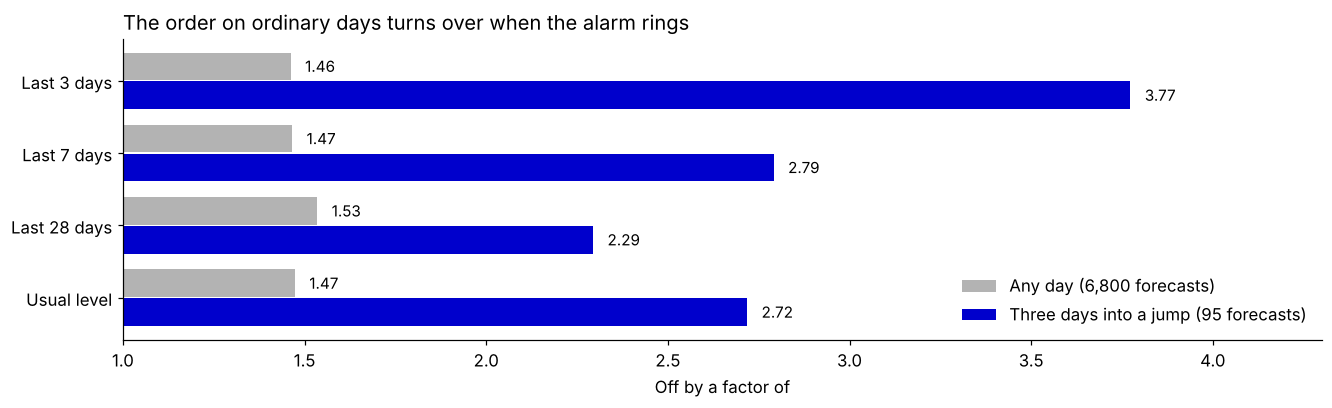

In [4]:
def cut(alarm_list, later=0):
    "One case per alarm, forecast so many days after it rang."
    return [cases_from_series(views[page], origins=[days + later], horizon=HORIZON, name=page)[0]
            for page, days in alarm_list]


after_alarm = cut(test)
jumped = {name: misses(model, after_alarm) for name, model in forecasters.items()}

both = pd.DataFrame({"Any day": {name: factor(log) for name, log in ordinary.items()},
                     "Three days into a jump": {name: factor(log) for name, log in jumped.items()}})
display(both.round(2).rename_axis("Off by a factor of"))
print("Further off than Last 28 days after an alarm, with a 95% interval:")
for name in ("Last 3 days", "Last 7 days", "Usual level"):
    mean, low, high = further_off(jumped[name], jumped["Last 28 days"])
    print(f"  {name:13s}{mean:+4.0f}%  ({low:+.0f}% to {high:+.0f}%)")

fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
place = np.arange(len(both))
ax.barh(place - 0.2, both["Any day"], height=0.38, color="0.7", label=f"Any day ({len(any_day):,} forecasts)")
ax.barh(place + 0.2, both["Three days into a jump"], height=0.38, color="#0000CC",
        label=f"Three days into a jump ({len(after_alarm)} forecasts)")
for where, column in ((-0.2, "Any day"), (0.2, "Three days into a jump")):
    for row, value in zip(place, both[column]):
        ax.text(value + 0.04, row + where, f"{value:.2f}", va="center", fontsize=10)
ax.set_yticks(place, both.index)
ax.invert_yaxis()
ax.set(title="The order on ordinary days turns over when the alarm rings", xlabel="Off by a factor of",
       xlim=(1, 4.3))
ax.legend(loc="lower right")
plt.show()

order = both["Three days into a jump"].sort_values().index.tolist()
clear = [further_off(jumped[name], jumped["Last 28 days"])[1] > 0 for name in order[1:]]
assert order == ["Last 28 days", "Usual level", "Last 7 days", "Last 3 days"] and all(clear)
assert np.allclose(both["Three days into a jump"], [3.77, 2.79, 2.29, 2.72], atol=0.006), both.round(3)

The order has turned over. The forecaster we were about to keep is off by a factor of 3.8, and the one we were about to drop is the best of the four at 2.3. Every gap to it is clear of zero. Nothing was wrong with the first backtest. It answered a question about ordinary days, and the alarm days are too few to move its average.

## What jumps do

To see why, look at what happens after a jump. The 125 alarms before the test year are the ones to look at, so that the test stays untouched. For each, the picture shows the page's views as a multiple of its usual level, from two weeks before the alarm to four weeks after.

TimeGym's scorecard has a way to put the question. It scores a forecaster on generated series of known kinds, and two of its kinds are the two things a jump can do: "shocks never fade" and "shocks fade".

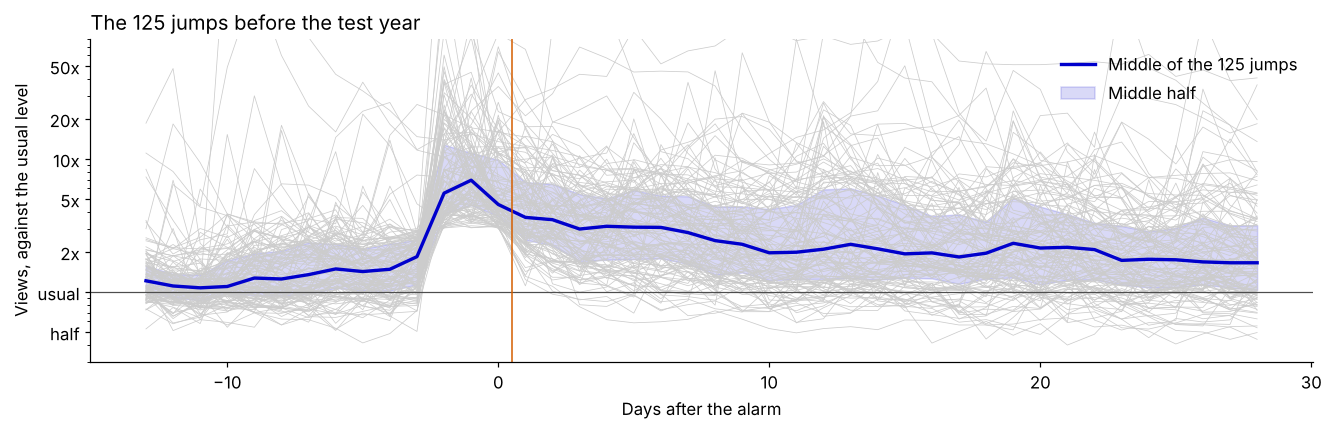

At the alarm the middle jump is 7.3 times the usual level.
In the fourth week after it, the middle page is at 1.6 times its usual level.
  20% of jumps still hold half their height or more,
  42% are still at twice the usual level or more,
  29% are back within a quarter of the usual level.


,Shocks never fade,Shocks fade
"Scorecard, out of 100",,
Last 3 days,96,70
Last 28 days,81,84
Usual level,61,87


In [5]:
def around(alarm_list, before=14):
    "Views from `before` days before each alarm to four weeks after, as multiples of the usual level."
    rows = []
    for page, days in alarm_list:
        values = views[page].to_numpy(float)
        shown = np.maximum(values[days - before: days + HORIZON], 1)        # no views counts as one
        rows.append(shown / usual_level(values[:days]))
    return np.array(rows)


paths = around(earlier)
height = paths[:, 14 - JUMP_DAYS: 14].mean(axis=1)             # the three days of the jump
week_four = np.median(paths[:, -7:], axis=1)                   # the fourth week after it
kept = (week_four - 1) / (height - 1)                          # share of the jump still there

fig, ax = plt.subplots(figsize=(12, 3.8), layout="constrained")
when = np.arange(-13, HORIZON + 1)
ax.plot(when, paths.T, color="0.8", linewidth=0.5)
ax.plot(when, np.median(paths, axis=0), color="#0000CC", linewidth=2.2, label="Middle of the 125 jumps")
ax.fill_between(when, *np.quantile(paths, [0.25, 0.75], axis=0), color="#0000CC", alpha=0.15,
                label="Middle half")
ax.axhline(1, color="0.3", linewidth=0.8)
ax.axvline(0.5, color="#D55E00", linewidth=1)
ax.set_yscale("log")
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50], ["half", "usual", "2x", "5x", "10x", "20x", "50x"])
ax.set(title=f"The {len(earlier)} jumps before the test year", xlabel="Days after the alarm",
       ylabel="Views, against the usual level", ylim=(0.3, 80))
ax.legend(loc="upper right")
plt.show()

print(f"At the alarm the middle jump is {np.median(height):.1f} times the usual level.")
print(f"In the fourth week after it, the middle page is at {np.median(week_four):.1f} times its usual level.")
print(f"  {100 * np.mean(kept >= 0.5):.0f}% of jumps still hold half their height or more,")
print(f"  {100 * np.mean(week_four >= 2):.0f}% are still at twice the usual level or more,")
print(f"  {100 * np.mean(np.abs(week_four - 1) <= 0.25):.0f}% are back within a quarter of the usual level.")
assert [round(100 * share) for share in (np.mean(kept >= 0.5), np.mean(np.abs(week_four - 1) <= 0.25))] == [20, 29]

rows = {}
for name in ("Last 3 days", "Last 28 days", "Usual level"):
    card = Pipeline(forecasters[name]).run(["random_walk", "mean_reverting"],
                                           history_length=120, horizon=HORIZON, instances=30).scorecard
    scores = card.table.groupby("title", sort=False)["score"].mean()
    rows[name] = {title.split(": ")[1].capitalize(): score for title, score in scores.items()}
scorecard = pd.DataFrame(rows).T
display(scorecard.round(0).astype(int).rename_axis("Scorecard, out of 100"))

assert (round(float(np.median(height)), 1), round(float(np.median(week_four)), 1)) == (7.3, 1.6)
assert scorecard["Shocks never fade"].idxmax() == "Last 3 days" and scorecard["Shocks fade"].idxmax() == "Usual level"
assert scorecard["Shocks never fade"].idxmin() == "Usual level" and scorecard["Shocks fade"].idxmin() == "Last 3 days"
assert np.allclose(scorecard.loc[["Last 3 days", "Usual level"]].to_numpy().ravel(), [96, 70, 61, 87], atol=1.5)

Neither the old level nor the new one. The middle jump takes a page to seven times its usual level, and four weeks later the middle page is at 1.6 times. One jump in five still holds half its height, and three in ten are back within a quarter of where they started.

The scorecard says what that means for each forecaster (each number is the average of its two noise levels, at 120 days of history and 28 days ahead). Where shocks never fade, following the last three days scores 96 out of 100 and the usual level 61. Where shocks fade, the usual level scores 87 and the last three days 70. The four-week average is in the middle on both, which is why it won after the alarm: with three days of the jump among its 28, it sits a little above the old level without having meant to.

## Learn the fade from earlier jumps

So build the forecaster that means to. It forecasts between the usual level and yesterday's, and how far toward yesterday is one number for each day ahead: how much of the jump to carry forward. A carry of 1 says shocks never fade, and 0 says they are gone tomorrow. The 28 numbers are fitted on the 125 earlier jumps, and TimeGym accepts the result like any other forecaster, because all it needs is `fit(history)` and `predict(dates)`.

,Off by a factor of,Week 1,Week 4
95 alarms,,,
Last 3 days,3.77,2.86,4.63
Last 7 days,2.79,2.26,3.27
Last 28 days,2.29,2.20,2.29
Usual level,2.72,3.37,2.20
"Fade, learned",2.04,1.85,2.02


Carry: 0.81 for tomorrow, 0.57 a week ahead, 0.31 four weeks ahead.
A page at 10 times its usual level is forecast at 6.4 times tomorrow and 2.0 times in four weeks.
Against Last 28 days: -11%  (-15% to -7%)


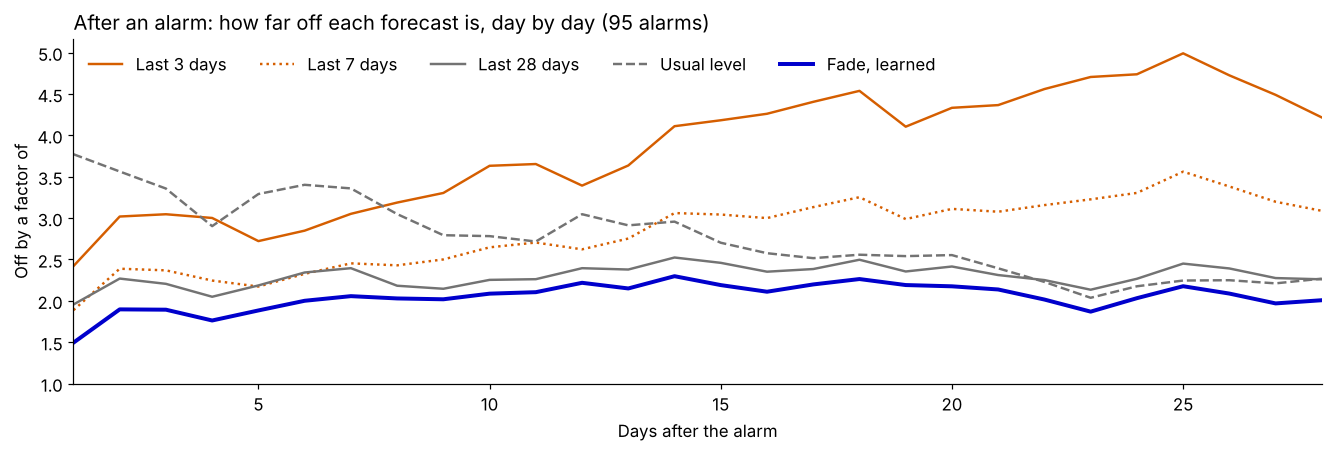

In [6]:
class Fade:
    "Between the usual level and yesterday's, closer to the usual level the further ahead."

    def __init__(self, carry):
        self.carry = carry            # for each day ahead, how much of yesterday's jump to carry forward

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        self.usual_ = usual_level(values)
        self.jump_ = values[-1] / self.usual_
        return self

    def predict(self, dates):
        return self.usual_ * self.jump_ ** np.asarray(self.carry)[:len(dates)]


learn = np.log(around(earlier, before=1))          # the last day of the jump, then the 28 days after
yesterday, came = learn[:, 0], learn[:, 1:]
carry = (yesterday[:, None] * came).sum(axis=0) / (yesterday ** 2).sum()   # least squares, per day ahead

jumped["Fade, learned"] = misses(Fade(carry), after_alarm)

result = pd.DataFrame({"Off by a factor of": {name: factor(log) for name, log in jumped.items()}})
result["Week 1"] = [factor(log[:, :7]) for log in jumped.values()]
result["Week 4"] = [factor(log[:, 21:]) for log in jumped.values()]
display(result.round(2).rename_axis(f"{len(after_alarm)} alarms"))

gain = further_off(jumped["Fade, learned"], jumped["Last 28 days"])
print(f"Carry: {carry[0]:.2f} for tomorrow, {carry[6]:.2f} a week ahead, {carry[-1]:.2f} four weeks ahead.")
print(f"A page at 10 times its usual level is forecast at {10 ** carry[0]:.1f} times tomorrow "
      f"and {10 ** carry[-1]:.1f} times in four weeks.")
print(f"Against Last 28 days: {gain[0]:+.0f}%  ({gain[1]:+.0f}% to {gain[2]:+.0f}%)")

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
day = np.arange(1, HORIZON + 1)
styles = {"Last 3 days": ("#D55E00", "-", 1.6), "Last 7 days": ("#D55E00", ":", 1.6),
          "Last 28 days": ("0.45", "-", 1.6), "Usual level": ("0.45", "--", 1.6),
          "Fade, learned": ("#0000CC", "-", 2.6)}
for name, (color, line, width) in styles.items():
    ax.plot(day, np.exp(jumped[name].mean(axis=0)), color=color, linestyle=line, linewidth=width, label=name)
ax.set(title=f"After an alarm: how far off each forecast is, day by day ({len(after_alarm)} alarms)",
       xlabel="Days after the alarm", ylabel="Off by a factor of", ylim=(1, None), xlim=(1, HORIZON))
ax.legend(ncols=5, loc="upper left")
plt.show()

assert result["Off by a factor of"].idxmin() == "Fade, learned" and gain[2] < 0
assert result["Week 1"].idxmin() == result["Week 4"].idxmin() == "Fade, learned"
assert result["Week 4"].drop("Fade, learned").idxmin() == "Usual level" and abs(carry[0] - 0.81) < 0.01 > abs(carry[-1] - 0.31)
assert abs(result.loc["Fade, learned", "Off by a factor of"] - 2.04) < 0.03, result.round(3)

The learned fade is off by a factor of 2.0, 11% closer than the four-week average, and the gain is clear of zero. Its carry is 0.81 for tomorrow and 0.31 four weeks ahead: a page at ten times its usual level is forecast at 6.4 times tomorrow and at twice in four weeks. It is the best of the five in the first week and in the fourth.

The picture shows what each of the others gets wrong. The last three days start close and get worse week after week, because they keep forecasting the jump. The usual level starts worst and is the best of the simple four by the fourth week. A factor of 2 is still a wide miss. Three days in, nobody knows which kind of jump this is, and no forecaster here can.

## How long the alarm lasts

One more run: the same alarms and the four simple forecasters, with the forecast made 3, 7 and 14 days after the alarm.

In [7]:
later = {}
for wait in (0, 3, 7, 14):
    cases = cut(test, later=wait)
    later[f"{wait} days later" if wait else "At the alarm"] = {
        name: factor(misses(model, cases)) for name, model in forecasters.items()}
later = pd.DataFrame(later)
display(later.round(2).rename_axis("Off by a factor of"))

assert later["At the alarm"].idxmax() == "Last 3 days" and later["14 days later"].idxmax() == "Last 28 days"
assert later.loc["Last 3 days", "7 days later"] < later.loc[["Last 7 days", "Last 28 days"], "7 days later"].min()
assert later["14 days later"].drop("Last 28 days").max() < 2.3 < 2.6 < later.loc["Last 28 days", "14 days later"]

,At the alarm,3 days later,7 days later,14 days later
Off by a factor of,,,,
Last 3 days,3.77,2.56,2.20,2.23
Last 7 days,2.79,3.28,2.48,2.23
Last 28 days,2.29,2.30,2.38,2.71
Usual level,2.72,2.51,2.30,2.01


An average is at its worst while the jump is fresh in its window. The last three days are the worst forecaster at the alarm and level with the best a week later, when the three days they look at are days after the peak. The four-week average, which won at the alarm, is the worst two weeks on, with the whole jump still inside its 28 days. By then the table looks like the ordinary one again: the four-week average last and the others close together. So the alarm day is the special one. In the first days after it, the forecast should come from what earlier jumps did, and two weeks later the ordinary choice is the right one again.

## What TimeGym added

- **The same forecasters on three sets of cases.** `cases_from_series` cuts a case wherever you say: every seventh day for the usual backtest, the alarm days for the second run, and the days after them for the third. Nothing else in the code changed between the tables.
- **Every forecast kept, day by day.** The lines that cross in the last picture come from the kept forecasts of one run for each forecaster.
- **Two rows of the scorecard that name the question.** "Shocks never fade" and "shocks fade" are the two things a jump can do, and the scorecard shows which forecaster suits which before any real jump is looked at.
- **A forecaster of our own in ten lines.** `Fade` went through the same pipeline as the others, and `paired_t_interval` on the same 95 alarms says its gain is clear of zero.

## Change one thing

- Change the alarm: `JUMP_SIZE = 2` or `5`, `JUMP_DAYS = 2` or `5`. Does the order after an alarm change?
- Give `Fade` the average of the three jump days in place of yesterday. Is it better or worse, and why might the last day know more?
- Fit a second set of carry numbers for forecasts made a week after the alarm. How much of what is left carries forward then?
- Run the alarm part on more pages: `load("wikipedia-views", full=True)` has 6,766 of them and several thousand alarms. Leave the any-day backtest on the sample; on every page it would run for about half an hour.

**What this doesn't show.** These are Wikipedia pages, not signups. A product launch may be a jump that stays, and then the carry numbers would be near 1 and the last three days the right forecaster. The way to find out is the one used here, on your own past jumps. The archive numbers the pages without naming them. The competition it took them from counted a page separately by device and for search engine robots, so the same page can be in the archive more than once and some series count robots, and the numbering does not say which. Some of the 95 alarms share a page or a day, so they are not 95 separate events, and the intervals are somewhat too narrow. The alarm rule is ours. In a run that is not part of this notebook, on all 67,656 pages of the archive that pass the same filter, the order of the four simple forecasters after an alarm was the same under six versions of the rule. The learned fade was ahead of them under five, and no better than the four-week average when the alarm rang after a single day.

**Related:** [Weekly shop sales](store-sales.ipynb) uses the scorecard's level-shift row to choose a forecaster, [Call center staffing](call-center.ipynb) is another job where the moment a forecast is made decides what it is worth, [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) covers cutting cases from a series of your own, and [Custom model](../tutorials/02_custom_model.ipynb) covers writing a forecaster with `fit` and `predict`. More examples are on the [examples page](../docs/examples.md).